In [1]:
import os
import random
from time import sleep

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output


Esta aula foi desenvolvida com esta versão da biblioteca `gym`:

In [2]:
gym.__version__

'1.4.0'

## Aprendizagem por reforço com Q-Learning

Neste exercícios, você vai utilizar o ambiente [CliffWalking](https://www.gymlibrary.dev/environments/toy_text/cliff_walking).

In [3]:
env = gym.make("CliffWalking-v1", render_mode="rgb_array")

Resete o ambiente.

In [4]:
estado, info = env.reset()

Este ambiente prevê que o personagem sempre retorna à célula 36 quando o ambiente é resetado.

Renderize o ambiente, passando o argumento `mode="rgb_array"`. Para visualizar a figura, a chamada para `render` deve ser passada para a função `plt.imshow`.

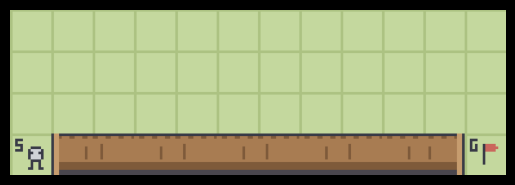

In [5]:
plt.imshow(env.render())
plt.axis("off")
plt.show()

Exiba o espaço de ações.

In [6]:
env.action_space

Discrete(4)

De acordo com a documentação:

> Existem 4 ações discretas determinísticas:
>
> 0: mover para cima
>
> 1: mover para a direita
>
> 2: mover para baixo
>
> 3: mover para a esquerda

Exiba o espaço de observações.

In [7]:
env.observation_space

Discrete(48)

De acordo com a documentação:

> O tabuleiro é uma matriz 4x12.

Isso fica evidente pela figura.

Exiba os estados possíveis junto com suas ações, probabilidades, novos estados, recompensas e status.

In [10]:
len(env.unwrapped.P)

48

Observe que as recompensas são iguais a $-1$ ou $-100$. De acordo com a documentação:

> Cada passo resulta em recompensa $-1$, e um passo no abismo resulta em recompensa $-100$.

Inicialize a tabela Q para armazenar a memória do treinamento, e exiba seu `shape`.

In [11]:
q_table = np.zeros([env.observation_space.n, env.action_space.n])
q_table.shape

(48, 4)

Agora, pode implementar o algoritmo Q-Learning, utilizando os mesmos parâmetros `alpha`, `gamma` e `epsilon` apresentados em aula. Como este ambiente é mais simples, pode repetir o treinamento por apenas 1000 episódios. Lembre-se de adequar o valor da recompensa na parte do script que contabiliza uma penalidade.

In [12]:
alpha = 0.1
gamma = 0.6
epsilon = 0.1

for i in range(1000):
    estado, info = env.reset()

    penalidade, recompensa = 0, 0
    done = False

    while not done:
        if random.uniform(0, 1) < epsilon:
            acao = env.action_space.sample()
        else:
            acao = np.argmax(q_table[estado])

        proximo_estado, recompensa, terminated, truncated, info = env.step(acao)
        done = terminated or truncated

        q_antigo = q_table[estado, acao]
        proximo_maximo = np.max(q_table[proximo_estado])

        q_novo = (1 - alpha) * q_antigo + alpha * (recompensa + gamma * proximo_maximo)
        q_table[estado, acao] = q_novo

        if recompensa == -100:
            penalidade += 1
        estado = proximo_estado
    if i % 100 == 0:
        clear_output(wait=True)
        print(f"Episódio: {i}")

print('Treinamento concluído')

Episódio: 900
Treinamento concluído


Resete e renderize o ambiente de novo.

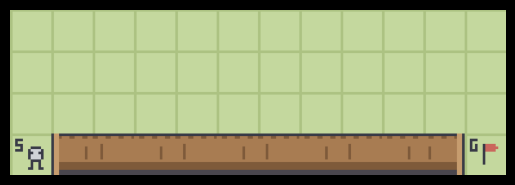

In [13]:
estado, info = env.reset()
plt.imshow(env.render())
plt.axis("off")
plt.show()

Agora dê um passo para a direita e renderize o ambiente.

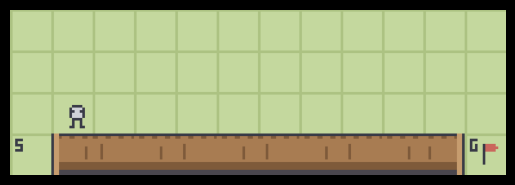

In [20]:
estado, recompensa, terminated, truncated, info = env.step(1)
plt.imshow(env.render())
plt.axis("off")
plt.show()

Como na direita existe o precipício, este ambiente foi configurado para que, neste caso, o personagem não saia do lugar (mas a recompensa recebida é $-100$).

Repita com um passo para cima.

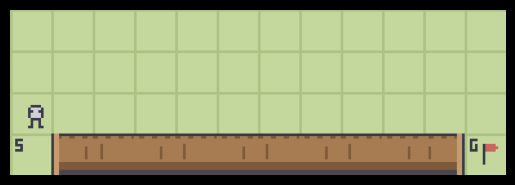

In [15]:
estado, recompensa, terminated, truncated, info = env.step(0)
plt.imshow(env.render())
plt.axis("off")
plt.show()

Agora sim o personagem se moveu.

Para verificar o resultado do treinamento, simule os passos no ambiente, fazendo uso da `q_table`. Como o personagem inicia sempre da mesma célula, não é necessário simular mais do que 1 episódio.

In [21]:
total_penalidade = 0
episodios = 50
frames = []

for _ in range(episodios):
    # 2. Desempacota estado e info
    estado, info = env.reset()
    penalidades, recompensa = 0, 0
    done = False

    while not done:
        acao = np.argmax(q_table[estado])

        # 3. Desempacota os 5 valores do step()
        estado, recompensa, terminated, truncated, info = env.step(acao)
        done = terminated or truncated

        # 4. Penalidade do penhasco no CliffWalking é -100
        if recompensa == -100:
            penalidades += 1

        frames.append({
            'frame': env.render(),  # Sem o parâmetro mode
            'state': estado,
            'action': acao,
            'reward': recompensa
        })

    total_penalidade += penalidades

print(f"Episódios: {episodios}")
print(f"Penalidades: {total_penalidade}")

Episódios: 50
Penalidades: 0


Exiba os frames, admitindo 1 segundo de intervalo entre as exibições.

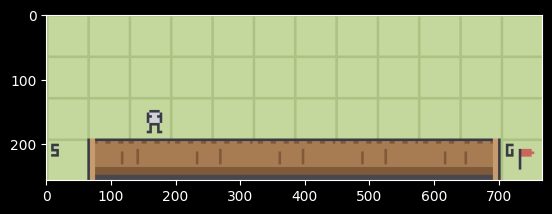

State 26
Action 1
Reward -1


KeyboardInterrupt: 

In [22]:
for frame in frames:
    clear_output(wait=True)
    plt.imshow(frame['frame'])
    plt.show()
    print('State', frame['state'])
    print('Action', frame['action'])
    print('Reward', frame['reward'])
    sleep(1)